In [118]:
import pandas as pd

In [119]:
import os
path = r"D:\APL Logistics\APL_Logistics.csv"
print(os.path.exists(path))

True


In [120]:
import os 
print (os.listdir("D:\APL Logistics"))

['APL_Logistics.csv', 'APL_Logistics.zip']


In [121]:
import pandas as pd

df = pd.read_csv("APL_Logistics.csv", encoding="latin1")

In [122]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,...,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,...,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,...,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,...,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,...,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class


In [123]:
df.shape

(180519, 40)

In [124]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Fname', 'Customer Id', 'Customer Lname',
       'Customer Segment', 'Customer State', 'Customer Street',
       'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude',
       'Longitude', 'Market', 'Order City', 'Order Country',
       'Order Customer Id', 'Order Item Discount', 'Order Item Discount Rate',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Product Name', 'Product Price', 'Shipping Mode'],
      dtype='object')

In [125]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 40 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Fname                 180519 non-null  object 
 12  Customer Id                   

In [126]:
df["Late_delivery_risk"].value_counts()
             

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

In [127]:
df[["Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Late_delivery_risk"]].head(10)

,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Late_delivery_risk
0,6,4,Late delivery,1
1,4,4,Shipping on time,0
2,4,4,Shipping on time,0
3,6,4,Late delivery,1
4,6,4,Late delivery,1
5,6,4,Late delivery,1
6,4,4,Shipping on time,0
7,4,4,Shipping on time,0
8,4,4,Shipping on time,0
9,4,4,Shipping on time,0


In [128]:
df.isnull().sum()

Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Benefit per order                0
Sales per customer               0
Delivery Status                  0
Late_delivery_risk               0
Category Id                      0
Category Name                    0
Customer City                    0
Customer Country                 0
Customer Fname                   0
Customer Id                      0
Customer Lname                   8
Customer Segment                 0
Customer State                   0
Customer Street                  0
Customer Zipcode                 3
Department Id                    0
Department Name                  0
Latitude                         0
Longitude                        0
Market                           0
Order City                       0
Order Country                    0
Order Customer Id                0
Order Item Discount              0
Order Item Discount Rate         0
Order Item Product P

In [129]:
df.duplicated().sum()

np.int64(0)

In [130]:
pd.crosstab(df["Delivery Status"], df["Late_delivery_risk"])

Late_delivery_risk,0,1
Delivery Status,,
Advance shipping,41592,0
Late delivery,0,98977
Shipping canceled,7754,0
Shipping on time,32196,0


In [131]:
df.dtypes

Type                              object
Days for shipping (real)           int64
Days for shipment (scheduled)      int64
Benefit per order                float64
Sales per customer               float64
Delivery Status                   object
Late_delivery_risk                 int64
Category Id                        int64
Category Name                     object
Customer City                     object
Customer Country                  object
Customer Fname                    object
Customer Id                        int64
Customer Lname                    object
Customer Segment                  object
Customer State                    object
Customer Street                   object
Customer Zipcode                 float64
Department Id                      int64
Department Name                   object
Latitude                         float64
Longitude                        float64
Market                            object
Order City                        object
Order Country   

In [132]:
features = [
    "Days for shipment (scheduled)",
    "Benefit per order",
    "Sales per customer",
    "Category Id",
    "Customer Segment",
    "Department Id",
    "Market",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Product Price",
    "Order Item Profit Ratio",
    "Order Item Quantity",
    "Order Region",
    "Product Price",
    "Shipping Mode"
]

In [133]:
target = "Late_delivery_risk"

In [134]:
df[features].head()

,Days for shipment (scheduled),Benefit per order,Sales per customer,Category Id,Customer Segment,Department Id,Market,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Order Region,Product Price,Shipping Mode
0,4,159.69,472.45,9,Consumer,3,Pacific Asia,27.50,0.06,99.99,0.34,5,South Asia,99.99,Standard Class
1,4,48.71,167.96,29,Consumer,5,LATAM,31.99,0.16,39.99,0.29,5,Central America,39.99,Standard Class
2,4,87.36,181.99,48,Consumer,7,LATAM,18.00,0.09,199.99,0.48,1,Central America,199.99,Standard Class
3,4,-41.89,175.99,48,Consumer,7,USCA,24.00,0.12,199.99,-0.24,1,East of USA,199.99,Standard Class
4,4,10.00,40.00,24,Consumer,5,USCA,10.00,0.20,50.00,0.25,1,East of USA,50.00,Standard Class


In [135]:
df[features].isnull().sum()

Days for shipment (scheduled)    0
Benefit per order                0
Sales per customer               0
Category Id                      0
Customer Segment                 0
Department Id                    0
Market                           0
Order Item Discount              0
Order Item Discount Rate         0
Order Item Product Price         0
Order Item Profit Ratio          0
Order Item Quantity              0
Order Region                     0
Product Price                    0
Shipping Mode                    0
dtype: int64

In [136]:
X = df[features]
y = df["Late_delivery_risk"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (180519, 15)
y shape: (180519,)


In [137]:
X[["Customer Segment", "Market", "Order Region", "Shipping Mode"]].nunique()

Customer Segment     3
Market               5
Order Region        23
Shipping Mode        4
dtype: int64

In [138]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [139]:
categorical_features = [
    "Customer Segment",
    "Market",
    "Order Region",
    "Shipping Mode"
]

numerical_features = [
    "Days for shipment (scheduled)",
    "Benefit per order",
    "Sales per customer",
    "Category Id",
    "Department Id",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Product Price",
    "Order Item Profit Ratio",
    "Order Item Quantity",
    "Product Price"
]

In [140]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

In [141]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [142]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (144415, 15)
X_test: (36104, 15)
y_train: (144415,)
y_test: (36104,)


In [143]:
stratify=y

In [144]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [145]:
print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

X_train_processed shape: (144415, 46)
X_test_processed shape: (36104, 46)


In [146]:
 from sklearn.linear_model import LogisticRegression

In [147]:
model = LogisticRegression(max_iter=1000)

In [148]:
max_iter=1000

In [149]:
from sklearn.preprocessing import StandardScaler

In [150]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numerical_features)
    ]
)

In [151]:
("num", "passthrough", numerical_features)

('num',
 'passthrough',
 ['Days for shipment (scheduled)',
  'Benefit per order',
  'Sales per customer',
  'Category Id',
  'Department Id',
  'Order Item Discount',
  'Order Item Discount Rate',
  'Order Item Product Price',
  'Order Item Profit Ratio',
  'Order Item Quantity',
  'Product Price'])

In [152]:
"passthrough"

'passthrough'

In [153]:
numerical_features = [
    'Days for shipment (scheduled)',
    'Benefit per order',
    'Sales per customer',
    'Category Id',
    'Department Id',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Order Item Product Price',
    'Order Item Profit Ratio',
    'Order Item Quantity',
    'Product Price'
]

categorical_features = [
    'Customer Segment',
    'Market',
    'Order Region',
    'Shipping Mode'
]

In [154]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

In [155]:
X = df.drop('Late_delivery_risk', axis=1)
y = df['Late_delivery_risk']

In [156]:
print(X.shape)
print(y.shape)

(180519, 39)
(180519,)


In [157]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(144415, 39)
(36104, 39)


In [158]:
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X_train.select_dtypes(
    include=['object']
).columns

print("Numerical:", list(numerical_features))
print("Categorical:", list(categorical_features))

Numerical: ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Id', 'Customer Id', 'Customer Zipcode', 'Department Id', 'Latitude', 'Longitude', 'Order Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Product Price']
Categorical: ['Type', 'Delivery Status', 'Category Name', 'Customer City', 'Customer Country', 'Customer Fname', 'Customer Lname', 'Customer Segment', 'Customer State', 'Customer Street', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Shipping Mode']


In [159]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

In [160]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [161]:
print(X_train_processed.shape)
print(X_test_processed.shape)

(144415, 14916)
(36104, 14916)


In [162]:
print("Numerical:", list(numerical_features))
print("Categorical:", list(categorical_features))

Numerical: ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Id', 'Customer Id', 'Customer Zipcode', 'Department Id', 'Latitude', 'Longitude', 'Order Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Product Price']
Categorical: ['Type', 'Delivery Status', 'Category Name', 'Customer City', 'Customer Country', 'Customer Fname', 'Customer Lname', 'Customer Segment', 'Customer State', 'Customer Street', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Shipping Mode']


In [163]:
selected_features = [
    'Days for shipping (real)',
    'Days for shipment (scheduled)',
    'Benefit per order',
    'Sales per customer',
    'Category Name',
    'Customer Segment',
    'Market',
    'Order Region',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Order Item Product Price',
    'Order Item Profit Ratio',
    'Order Item Quantity',
    'Shipping Mode',
    'Sales'
]

X = df[selected_features]
y = df['Late_delivery_risk']

In [164]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(144415, 15)
(36104, 15)


In [165]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(144415, 15)
(36104, 15)


In [166]:
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X_train.select_dtypes(
    include=['object']
).columns

In [167]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

In [168]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [169]:
print("Starting preprocessing...")

X_train_processed = preprocessor.fit_transform(X_train)

print("Training data processed!")

X_test_processed = preprocessor.transform(X_test)

print("Test data processed!")

print("Train shape:", X_train_processed.shape)
print("Test shape:", X_test_processed.shape)

Starting preprocessing...
Training data processed!
Test data processed!
Train shape: (144415, 95)
Test shape: (36104, 95)


In [170]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_processed, y_train)

print("Model training completed!")

Model training completed!


In [171]:
y_pred = model.predict(X_test_processed)

print(y_pred[:20])

[1 0 0 0 1 0 1 0 1 1 0 1 0 0 1 0 1 1 1 1]


In [172]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy %:", accuracy * 100)

Accuracy: 0.9758752492798581
Accuracy %: 97.58752492798581


In [173]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[15437   871]
 [    0 19796]]


In [174]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97     16308
           1       0.96      1.00      0.98     19796

    accuracy                           0.98     36104
   macro avg       0.98      0.97      0.98     36104
weighted avg       0.98      0.98      0.98     36104



In [175]:
print(selected_features)

['Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Region', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Shipping Mode', 'Sales']


In [176]:
selected_features_safe = [
    'Days for shipment (scheduled)',
    'Benefit per order',
    'Sales per customer',
    'Category Name',
    'Customer Segment',
    'Market',
    'Order Region',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Order Item Product Price',
    'Order Item Profit Ratio',
    'Order Item Quantity',
    'Shipping Mode',
    'Sales'
]

In [177]:
X = df[selected_features_safe]
y = df['Late_delivery_risk']

In [178]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(144415, 14)
(36104, 14)


In [179]:
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X_train.select_dtypes(
    include=['object']
).columns

In [180]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [181]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(X_train_processed.shape)
print(X_test_processed.shape)

(144415, 94)
(36104, 94)


In [182]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_processed, y_train)

print("Model training completed!")

Model training completed!


In [183]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_processed)

print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred))

Accuracy: 0.6963494349656548

              precision    recall  f1-score   support

           0       0.61      0.88      0.72     16308
           1       0.85      0.54      0.66     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.71      0.69     36104
weighted avg       0.74      0.70      0.69     36104



In [184]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [185]:
y_pred_rf = rf_model.predict(X_test_processed)

In [186]:
from sklearn.metrics import accuracy_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)

Random Forest Accuracy: 0.6501218701528917


In [187]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.60      0.65      0.63     16308
           1       0.69      0.65      0.67     19796

    accuracy                           0.65     36104
   macro avg       0.65      0.65      0.65     36104
weighted avg       0.65      0.65      0.65     36104



In [188]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Confusion Matrix:")
print(cm_rf)

Confusion Matrix:
[[10609  5699]
 [ 6933 12863]]


In [189]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.60      0.65      0.63     16308
           1       0.69      0.65      0.67     19796

    accuracy                           0.65     36104
   macro avg       0.65      0.65      0.65     36104
weighted avg       0.65      0.65      0.65     36104



In [190]:
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy: 0.6501218701528917


In [191]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.60      0.65      0.63     16308
           1       0.69      0.65      0.67     19796

    accuracy                           0.65     36104
   macro avg       0.65      0.65      0.65     36104
weighted avg       0.65      0.65      0.65     36104



In [192]:
feature_names = preprocessor.get_feature_names_out()

In [193]:
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

In [194]:
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

In [195]:
print(feature_importance.head(15))

                               Feature  Importance
1               num__Benefit per order    0.177718
6         num__Order Item Profit Ratio    0.157907
2              num__Sales per customer    0.075974
3             num__Order Item Discount    0.073085
0   num__Days for shipment (scheduled)    0.067492
93   cat__Shipping Mode_Standard Class    0.066704
4        num__Order Item Discount Rate    0.063241
90      cat__Shipping Mode_First Class    0.051002
8                           num__Sales    0.025712
92     cat__Shipping Mode_Second Class    0.021410
5        num__Order Item Product Price    0.018574
7             num__Order Item Quantity    0.014632
59      cat__Customer Segment_Consumer    0.013096
60     cat__Customer Segment_Corporate    0.010944
61   cat__Customer Segment_Home Office    0.010423


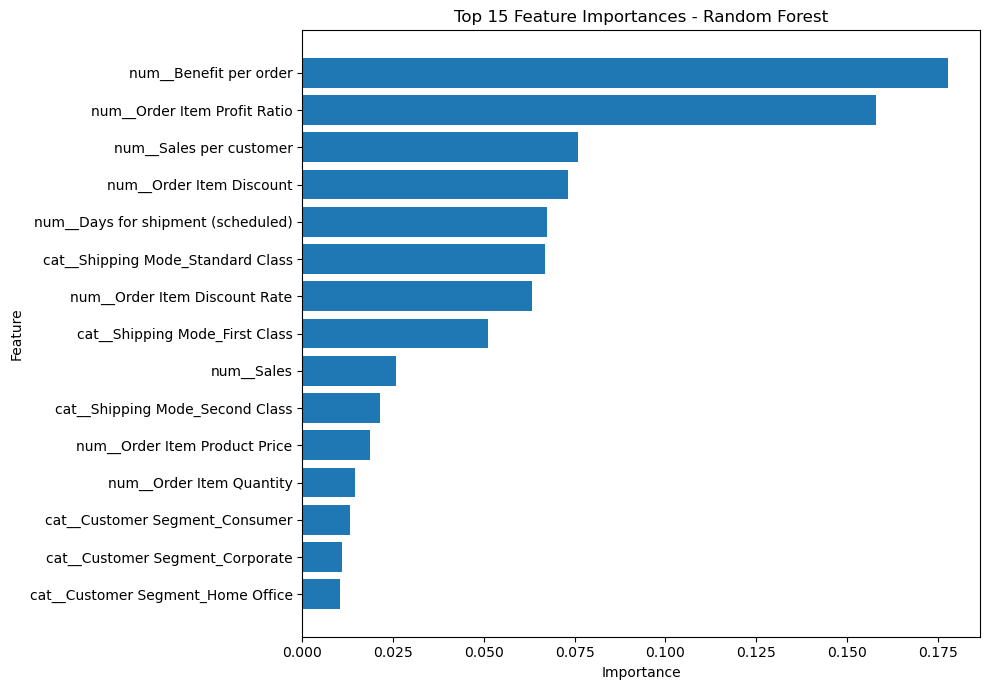

In [197]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by='Importance'
)

plt.figure(figsize=(10, 7))
plt.barh(top_features['Feature'], top_features['Importance'])

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 15 Feature Importances - Random Forest')

plt.tight_layout()
plt.show()

In [198]:
print(X.columns.tolist())

['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Region', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Shipping Mode', 'Sales']


In [199]:
print(df[['Late_delivery_risk',
          'Benefit per order',
          'Sales per customer',
          'Order Item Discount',
          'Order Item Discount Rate',
          'Order Item Profit Ratio',
          'Sales']].head())

   Late_delivery_risk  Benefit per order  Sales per customer  \
0                   1             159.69              472.45   
1                   0              48.71              167.96   
2                   0              87.36              181.99   
3                   1             -41.89              175.99   
4                   1              10.00               40.00   

   Order Item Discount  Order Item Discount Rate  Order Item Profit Ratio  \
0                27.50                      0.06                     0.34   
1                31.99                      0.16                     0.29   
2                18.00                      0.09                     0.48   
3                24.00                      0.12                    -0.24   
4                10.00                      0.20                     0.25   

    Sales  
0  499.95  
1  199.95  
2  199.99  
3  199.99  
4   50.00  


In [200]:
print(df[['Late_delivery_risk',
          'Benefit per order',
          'Sales per customer',
          'Order Item Discount',
          'Order Item Discount Rate',
          'Order Item Profit Ratio',
          'Sales']].corr())

                          Late_delivery_risk  Benefit per order  \
Late_delivery_risk                  1.000000          -0.003727   
Benefit per order                  -0.003727           1.000000   
Sales per customer                 -0.003791           0.133484   
Order Item Discount                -0.000750           0.064756   
Order Item Discount Rate            0.000404          -0.018644   
Order Item Profit Ratio            -0.002316           0.823689   
Sales                              -0.003564           0.131816   

                          Sales per customer  Order Item Discount  \
Late_delivery_risk                 -0.003791            -0.000750   
Benefit per order                   0.133484             0.064756   
Sales per customer                  1.000000             0.498734   
Order Item Discount                 0.498734             1.000000   
Order Item Discount Rate           -0.119469             0.659955   
Order Item Profit Ratio            -0.001439     

In [201]:
print(df[['Late_delivery_risk',
          'Benefit per order',
          'Sales per customer',
          'Order Item Discount',
          'Order Item Discount Rate',
          'Order Item Profit Ratio',
          'Sales']].corr())

                          Late_delivery_risk  Benefit per order  \
Late_delivery_risk                  1.000000          -0.003727   
Benefit per order                  -0.003727           1.000000   
Sales per customer                 -0.003791           0.133484   
Order Item Discount                -0.000750           0.064756   
Order Item Discount Rate            0.000404          -0.018644   
Order Item Profit Ratio            -0.002316           0.823689   
Sales                              -0.003564           0.131816   

                          Sales per customer  Order Item Discount  \
Late_delivery_risk                 -0.003791            -0.000750   
Benefit per order                   0.133484             0.064756   
Sales per customer                  1.000000             0.498734   
Order Item Discount                 0.498734             1.000000   
Order Item Discount Rate           -0.119469             0.659955   
Order Item Profit Ratio            -0.001439     

In [202]:
print([name for name in globals() if isinstance(globals()[name], pd.DataFrame)])

['df', '_5', '_10', '_13', '_17', 'X', 'X_train', 'X_test', 'feature_importance', 'top_features', 'results', '_94', '_95', '_97', '_99', '_101', '_105', 'threshold_comparison', 'business_insights', '_122', '_127', '_130', '_134']


In [203]:
# Step 1: Load the saved predictions
import pandas as pd

results = pd.read_csv(
    "late_delivery_risk_predictions.csv"
)

# Step 2: Update the risk categories
results["Risk_Level"] = pd.cut(
    results["Late_Risk_Score"],
    bins=[0, 0.30, 0.70, 1.01],
    labels=["Low", "Medium", "High"],
    right=False,
    include_lowest=True
)

# Step 3: Check the risk distribution
print("Updated Risk Distribution:")
print(results["Risk_Level"].value_counts())

Updated Risk Distribution:
Risk_Level
Medium    15212
High      12524
Low        8368
Name: count, dtype: int64


In [204]:
%whos

Variable                 Type                      Data/Info
------------------------------------------------------------
ColumnTransformer        ABCMeta                   <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
LogisticRegression       type                      <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OneHotEncoder            type                      <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
RandomForestClassifier   ABCMeta                   <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
StandardScaler           type                      <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                        DataFrame                 Shape: (180519, 14)
X_test                   DataFrame                 Shape: (36104, 14)
X_test_processed         csr_matrix                <Compressed Sparse Row sp<...>2)	1.0\n  (36103, 93)	1.0
X_train                  DataFrame                 Shape: (144415, 14)
X_train_processed       

In [205]:
import os

print("Predictions file exists:",
      os.path.exists("late_delivery_risk_predictions.csv"))

print("Current X_test shape:", X_test.shape)
print("Current y_test shape:", y_test.shape)
print("Current y_pred length:", len(y_pred))

Predictions file exists: True
Current X_test shape: (36104, 14)
Current y_test shape: (36104,)
Current y_pred length: 36104


In [206]:
from sklearn.metrics import roc_auc_score

# Prediction probabilities
y_prob_lr = model.predict_proba(X_test_processed)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

# ROC-AUC
auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Logistic Regression ROC-AUC:", auc_lr)
print("Random Forest ROC-AUC:", auc_rf)

Logistic Regression ROC-AUC: 0.731527277581342
Random Forest ROC-AUC: 0.7076084295031296


In [207]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Logistic Regression predictions
y_pred_lr = model.predict(X_test_processed)

# Accuracy
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.6963494349656548

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.88      0.72     16308
           1       0.85      0.54      0.66     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.71      0.69     36104
weighted avg       0.74      0.70      0.69     36104


Confusion Matrix:
[[14410  1898]
 [ 9065 10731]]


In [208]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Logistic Regression
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

# Random Forest
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Logistic Regression")
print("Precision:", precision_lr)
print("Recall:", recall_lr)
print("F1 Score:", f1_lr)

print("\nRandom Forest")
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1 Score:", f1_rf)

Logistic Regression
Precision: 0.8497109826589595
Recall: 0.5420792079207921
F1 Score: 0.6618966846569005

Random Forest
Precision: 0.6929748949466652
Recall: 0.6497777328753284
F1 Score: 0.6706814745294333


In [209]:
from sklearn.metrics import classification_report, confusion_matrix

# Get probability of Late Delivery Risk = 1
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

# Change threshold
threshold = 0.40

y_pred_rf_40 = (y_prob_rf >= threshold).astype(int)

print("Random Forest - Threshold 0.40")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_40))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_40))

Random Forest - Threshold 0.40

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.48      0.54     16308
           1       0.64      0.74      0.69     19796

    accuracy                           0.63     36104
   macro avg       0.62      0.61      0.61     36104
weighted avg       0.62      0.63      0.62     36104


Confusion Matrix:
[[ 7863  8445]
 [ 5050 14746]]


In [210]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

for threshold in thresholds:
    y_pred = (y_prob_rf >= threshold).astype(int)

    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")
    print(f"F1 Score:  {f1:.3f}")
    print("-" * 30)

Threshold: 0.3
Precision: 0.598
Recall:    0.838
F1 Score:  0.698
------------------------------
Threshold: 0.35
Precision: 0.616
Recall:    0.791
F1 Score:  0.692
------------------------------
Threshold: 0.4
Precision: 0.636
Recall:    0.745
F1 Score:  0.686
------------------------------
Threshold: 0.45
Precision: 0.662
Recall:    0.700
F1 Score:  0.680
------------------------------
Threshold: 0.5
Precision: 0.690
Recall:    0.656
F1 Score:  0.672
------------------------------
Threshold: 0.55
Precision: 0.714
Recall:    0.614
F1 Score:  0.660
------------------------------
Threshold: 0.6
Precision: 0.739
Recall:    0.577
F1 Score:  0.648
------------------------------


In [211]:
from sklearn.metrics import classification_report, confusion_matrix

final_threshold = 0.30

final_prob = rf_model.predict_proba(X_test_processed)[:, 1]

final_pred = (final_prob >= final_threshold).astype(int)

print("Final Random Forest Model")
print("Threshold:", final_threshold)

print("\nClassification Report:")
print(classification_report(y_test, final_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_pred))

Final Random Forest Model
Threshold: 0.3

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.32      0.42     16308
           1       0.60      0.84      0.70     19796

    accuracy                           0.60     36104
   macro avg       0.61      0.58      0.56     36104
weighted avg       0.61      0.60      0.57     36104


Confusion Matrix:
[[ 5155 11153]
 [ 3213 16583]]


In [212]:
# Create final prediction dataframe

results = X_test.copy()

results['Actual_Late_Risk'] = y_test.values
results['Late_Risk_Score'] = final_prob
results['Predicted_Late_Risk'] = final_pred

results.head(10)

,Days for shipment (scheduled),Benefit per order,Sales per customer,Category Name,Customer Segment,Market,Order Region,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Shipping Mode,Sales,Actual_Late_Risk,Late_Risk_Score,Predicted_Late_Risk
69318,4,-45.35,56.69,Cleats,Home Office,LATAM,South America,3.30,0.06,59.99,-0.80,1,Standard Class,59.99,0,0.480000,1
84032,4,10.54,169.99,Water Sports,Corporate,Europe,Western Europe,30.00,0.15,199.99,0.06,1,Standard Class,199.99,0,0.310000,1
160369,4,11.31,113.09,Men's Footwear,Consumer,Europe,Western Europe,16.90,0.13,129.99,0.10,1,Standard Class,129.99,0,0.170000,0
149768,4,-17.76,92.96,Indoor/Outdoor Games,Corporate,Europe,Western Europe,7.00,0.07,49.98,-0.19,2,Standard Class,99.96,0,0.182000,0
107905,4,84.47,263.98,Camping & Hiking,Corporate,LATAM,Central America,36.00,0.12,299.98,0.32,1,Standard Class,299.98,1,0.300000,1
130552,4,11.21,127.39,Men's Footwear,Consumer,Pacific Asia,Oceania,2.60,0.02,129.99,0.09,1,Standard Class,129.99,0,0.343333,1
153004,4,53.95,165.99,Water Sports,Corporate,Pacific Asia,Oceania,34.00,0.17,199.99,0.33,1,Standard Class,199.99,1,0.325833,1
70382,4,41.36,88.00,Women's Apparel,Corporate,Europe,Western Europe,12.00,0.12,50.00,0.47,2,Standard Class,100.00,0,0.310000,1
149022,2,34.40,122.84,Men's Footwear,Home Office,Europe,Northern Europe,7.15,0.06,129.99,0.28,1,Second Class,129.99,1,0.906667,1
3231,4,30.94,91.00,Women's Apparel,Corporate,USCA,US Center,9.00,0.09,50.00,0.34,2,Standard Class,100.00,1,0.260000,0


In [213]:
results['Risk_Level'] = pd.cut(
    results['Late_Risk_Score'],
    bins=[0, 0.30, 0.70, 1.0],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

results.head(10)

,Days for shipment (scheduled),Benefit per order,Sales per customer,Category Name,Customer Segment,Market,Order Region,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Shipping Mode,Sales,Actual_Late_Risk,Late_Risk_Score,Predicted_Late_Risk,Risk_Level
69318,4,-45.35,56.69,Cleats,Home Office,LATAM,South America,3.30,0.06,59.99,-0.80,1,Standard Class,59.99,0,0.480000,1,Medium
84032,4,10.54,169.99,Water Sports,Corporate,Europe,Western Europe,30.00,0.15,199.99,0.06,1,Standard Class,199.99,0,0.310000,1,Medium
160369,4,11.31,113.09,Men's Footwear,Consumer,Europe,Western Europe,16.90,0.13,129.99,0.10,1,Standard Class,129.99,0,0.170000,0,Low
149768,4,-17.76,92.96,Indoor/Outdoor Games,Corporate,Europe,Western Europe,7.00,0.07,49.98,-0.19,2,Standard Class,99.96,0,0.182000,0,Low
107905,4,84.47,263.98,Camping & Hiking,Corporate,LATAM,Central America,36.00,0.12,299.98,0.32,1,Standard Class,299.98,1,0.300000,1,Low
130552,4,11.21,127.39,Men's Footwear,Consumer,Pacific Asia,Oceania,2.60,0.02,129.99,0.09,1,Standard Class,129.99,0,0.343333,1,Medium
153004,4,53.95,165.99,Water Sports,Corporate,Pacific Asia,Oceania,34.00,0.17,199.99,0.33,1,Standard Class,199.99,1,0.325833,1,Medium
70382,4,41.36,88.00,Women's Apparel,Corporate,Europe,Western Europe,12.00,0.12,50.00,0.47,2,Standard Class,100.00,0,0.310000,1,Medium
149022,2,34.40,122.84,Men's Footwear,Home Office,Europe,Northern Europe,7.15,0.06,129.99,0.28,1,Second Class,129.99,1,0.906667,1,High
3231,4,30.94,91.00,Women's Apparel,Corporate,USCA,US Center,9.00,0.09,50.00,0.34,2,Standard Class,100.00,1,0.260000,0,Low


In [214]:
print(results['Risk_Level'].value_counts())

Risk_Level
Medium    15056
High      12328
Low        8720
Name: count, dtype: int64


In [215]:
# View the final prediction results

results[['Late_Risk_Score',
         'Predicted_Late_Risk',
         'Risk_Level']].head(20)

,Late_Risk_Score,Predicted_Late_Risk,Risk_Level
69318,0.480000,1,Medium
84032,0.310000,1,Medium
160369,0.170000,0,Low
149768,0.182000,0,Low
107905,0.300000,1,Low
130552,0.343333,1,Medium
153004,0.325833,1,Medium
70382,0.310000,1,Medium
149022,0.906667,1,High
3231,0.260000,0,Low


In [216]:
results.to_csv(
    'late_delivery_risk_predictions.csv',
    index=False
)

print("File saved successfully.")

File saved successfully.


In [217]:
# View the final prediction results

results[['Late_Risk_Score',
         'Predicted_Late_Risk',
         'Risk_Level']].head(20)

,Late_Risk_Score,Predicted_Late_Risk,Risk_Level
69318,0.480000,1,Medium
84032,0.310000,1,Medium
160369,0.170000,0,Low
149768,0.182000,0,Low
107905,0.300000,1,Low
130552,0.343333,1,Medium
153004,0.325833,1,Medium
70382,0.310000,1,Medium
149022,0.906667,1,High
3231,0.260000,0,Low


In [218]:
results.to_csv(
    'late_delivery_risk_predictions.csv',
    index=False
)

print("File saved successfully.")

File saved successfully.


In [219]:
feature_importance.head(10)

,Feature,Importance
1,num__Benefit per order,0.177718
6,num__Order Item Profit Ratio,0.157907
2,num__Sales per customer,0.075974
3,num__Order Item Discount,0.073085
0,num__Days for shipment (scheduled),0.067492
93,cat__Shipping Mode_Standard Class,0.066704
4,num__Order Item Discount Rate,0.063241
90,cat__Shipping Mode_First Class,0.051002
8,num__Sales,0.025712
92,cat__Shipping Mode_Second Class,0.021410


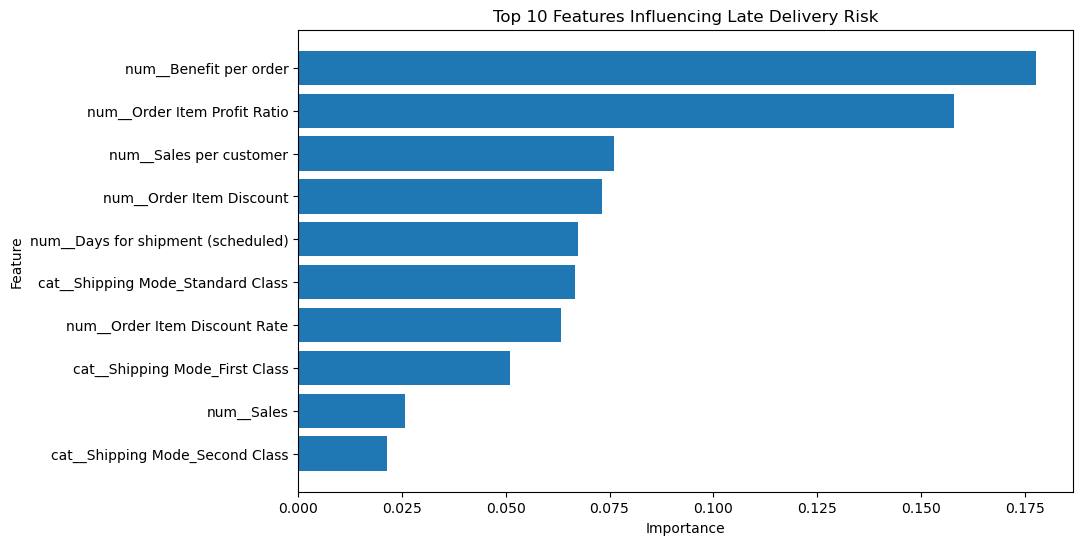

In [220]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 10 Features Influencing Late Delivery Risk')
plt.gca().invert_yaxis()
plt.show()

In [221]:
print("FINAL PROJECT INSIGHTS")
print("=" * 50)

print("\n1. Model Performance")
print("Random Forest Recall:", recall_score(y_test, final_pred))
print("Random Forest Precision:", precision_score(y_test, final_pred))
print("Random Forest F1:", f1_score(y_test, final_pred))

print("\n2. Risk Distribution")
print(results['Risk_Level'].value_counts())

print("\n3. Top 10 Important Features")
print(feature_importance[['Feature', 'Importance']].head(10))

FINAL PROJECT INSIGHTS

1. Model Performance
Random Forest Recall: 0.8376944837340877
Random Forest Precision: 0.5978872223824633
Random Forest F1: 0.6977615080366911

2. Risk Distribution
Risk_Level
Medium    15056
High      12328
Low        8720
Name: count, dtype: int64

3. Top 10 Important Features
                               Feature  Importance
1               num__Benefit per order    0.177718
6         num__Order Item Profit Ratio    0.157907
2              num__Sales per customer    0.075974
3             num__Order Item Discount    0.073085
0   num__Days for shipment (scheduled)    0.067492
93   cat__Shipping Mode_Standard Class    0.066704
4        num__Order Item Discount Rate    0.063241
90      cat__Shipping Mode_First Class    0.051002
8                           num__Sales    0.025712
92     cat__Shipping Mode_Second Class    0.021410


In [222]:
import os

print(os.path.exists("late_delivery_risk_predictions.csv"))

True


In [223]:
import pandas as pd

results = pd.read_csv("late_delivery_risk_predictions.csv")

print("Shape:", results.shape)
print("\nColumns:")
print(results.columns.tolist())

results.head()

Shape: (36104, 18)

Columns:
['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Region', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Shipping Mode', 'Sales', 'Actual_Late_Risk', 'Late_Risk_Score', 'Predicted_Late_Risk', 'Risk_Level']


,Days for shipment (scheduled),Benefit per order,Sales per customer,Category Name,Customer Segment,Market,Order Region,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Shipping Mode,Sales,Actual_Late_Risk,Late_Risk_Score,Predicted_Late_Risk,Risk_Level
0,4,-45.35,56.69,Cleats,Home Office,LATAM,South America,3.3,0.06,59.99,-0.80,1,Standard Class,59.99,0,0.480,1,Medium
1,4,10.54,169.99,Water Sports,Corporate,Europe,Western Europe,30.0,0.15,199.99,0.06,1,Standard Class,199.99,0,0.310,1,Medium
2,4,11.31,113.09,Men's Footwear,Consumer,Europe,Western Europe,16.9,0.13,129.99,0.10,1,Standard Class,129.99,0,0.170,0,Low
3,4,-17.76,92.96,Indoor/Outdoor Games,Corporate,Europe,Western Europe,7.0,0.07,49.98,-0.19,2,Standard Class,99.96,0,0.182,0,Low
4,4,84.47,263.98,Camping & Hiking,Corporate,LATAM,Central America,36.0,0.12,299.98,0.32,1,Standard Class,299.98,1,0.300,1,Low


In [224]:
print("Data shape:", results.shape)

print("\nCurrent Risk Distribution:")
print(results["Risk_Level"].value_counts(dropna=False))

print("\nMissing Risk Labels:")
print(results["Risk_Level"].isna().sum())

print("\nPredicted late-risk orders:")
print((results["Predicted_Late_Risk"] == 1).sum())

print("\nLate-risk orders with Low risk label:")
print(
    ((results["Predicted_Late_Risk"] == 1) &
     (results["Risk_Level"] == "Low")).sum()
)

Data shape: (36104, 18)

Current Risk Distribution:
Risk_Level
Medium    15056
High      12328
Low        8720
Name: count, dtype: int64

Missing Risk Labels:
0

Predicted late-risk orders:
27736

Late-risk orders with Low risk label:
352


In [225]:
print("Predicted risk vs risk label:")

print(pd.crosstab(
    results["Predicted_Late_Risk"],
    results["Risk_Level"],
    margins=True
))

print("\nLate-risk predictions with scores below 0.30:")

print(
    results.loc[
        (results["Predicted_Late_Risk"] == 1) &
        (results["Late_Risk_Score"] < 0.30),
        ["Late_Risk_Score", "Predicted_Late_Risk", "Risk_Level"]
    ].head(10)
)

Predicted risk vs risk label:
Risk_Level            High   Low  Medium    All
Predicted_Late_Risk                            
0                        0  8368       0   8368
1                    12328   352   15056  27736
All                  12328  8720   15056  36104

Late-risk predictions with scores below 0.30:
Empty DataFrame
Columns: [Late_Risk_Score, Predicted_Late_Risk, Risk_Level]
Index: []


In [226]:
results["Risk_Level"] = pd.cut(
    results["Late_Risk_Score"],
    bins=[0, 0.30, 0.70, 1.01],
    labels=["Low", "Medium", "High"],
    right=False,
    include_lowest=True
)

print("Updated Risk Distribution:")
print(results["Risk_Level"].value_counts())

print("\nMissing Risk Labels:")
print(results["Risk_Level"].isna().sum())

print("\nPredicted late-risk orders labelled Low:")
print(
    ((results["Predicted_Late_Risk"] == 1) &
     (results["Risk_Level"] == "Low")).sum()
)

Updated Risk Distribution:
Risk_Level
Medium    15212
High      12524
Low        8368
Name: count, dtype: int64

Missing Risk Labels:
0

Predicted late-risk orders labelled Low:
0


In [227]:
results.to_csv(
    "late_delivery_risk_predictions.csv",
    index=False
)

print("Corrected predictions saved successfully!")
print("Total orders:", len(results))

Corrected predictions saved successfully!
Total orders: 36104


In [228]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_true = results["Actual_Late_Risk"]
y_pred = results["Predicted_Late_Risk"]
y_score = results["Late_Risk_Score"]

print("MODEL PERFORMANCE")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, y_score), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

MODEL PERFORMANCE
----------------------------------------
Accuracy: 0.6021
Precision: 0.5979
Recall: 0.8377
F1 Score: 0.6978
ROC-AUC: 0.7076

Confusion Matrix:
[[ 5155 11153]
 [ 3213 16583]]

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.32      0.42     16308
           1       0.60      0.84      0.70     19796

    accuracy                           0.60     36104
   macro avg       0.61      0.58      0.56     36104
weighted avg       0.61      0.60      0.57     36104



In [229]:
print("Unique predicted labels:")
print(results["Predicted_Late_Risk"].value_counts())

print("\nActual labels:")
print(results["Actual_Late_Risk"].value_counts())

print("\nMean predicted risk score:")
print(round(results["Late_Risk_Score"].mean(), 4))

Unique predicted labels:
Predicted_Late_Risk
1    27736
0     8368
Name: count, dtype: int64

Actual labels:
Actual_Late_Risk
1    19796
0    16308
Name: count, dtype: int64

Mean predicted risk score:
0.5492


In [230]:
print("Predictions using a 0.30 threshold:")
print((results["Late_Risk_Score"] >= 0.30).sum())

print("\nPredictions using a 0.50 threshold:")
print((results["Late_Risk_Score"] >= 0.50).sum())

print("\nPredictions using a 0.70 threshold:")
print((results["Late_Risk_Score"] >= 0.70).sum())

Predictions using a 0.30 threshold:
27736

Predictions using a 0.50 threshold:
18809

Predictions using a 0.70 threshold:
12524


In [231]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_true = results["Actual_Late_Risk"]
scores = results["Late_Risk_Score"]

for threshold in [0.30, 0.50, 0.70]:
    y_pred_threshold = (scores >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", round(
        accuracy_score(y_true, y_pred_threshold), 4
    ))
    print("Precision:", round(
        precision_score(y_true, y_pred_threshold), 4
    ))
    print("Recall:", round(
        recall_score(y_true, y_pred_threshold), 4
    ))
    print("F1 Score:", round(
        f1_score(y_true, y_pred_threshold), 4
    ))


Threshold: 0.3
Accuracy: 0.6021
Precision: 0.5979
Recall: 0.8377
F1 Score: 0.6978

Threshold: 0.5
Accuracy: 0.6497
Precision: 0.69
Recall: 0.6556
F1 Score: 0.6724

Threshold: 0.7
Accuracy: 0.6536
Precision: 0.791
Recall: 0.5005
F1 Score: 0.6131


In [232]:
threshold_results = []

for threshold in [0.30, 0.50, 0.70]:
    predictions = (
        results["Late_Risk_Score"] >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            results["Actual_Late_Risk"], predictions
        ),
        "Precision": precision_score(
            results["Actual_Late_Risk"], predictions
        ),
        "Recall": recall_score(
            results["Actual_Late_Risk"], predictions
        ),
        "F1_Score": f1_score(
            results["Actual_Late_Risk"], predictions
        )
    })

threshold_comparison = pd.DataFrame(threshold_results)

print(threshold_comparison.round(4))

threshold_comparison.to_csv(
    "threshold_comparison.csv", index=False
)

print("\nThreshold comparison saved successfully!")

   Threshold  Accuracy  Precision  Recall  F1_Score
0        0.3    0.6021     0.5979  0.8377    0.6978
1        0.5    0.6497     0.6900  0.6556    0.6724
2        0.7    0.6536     0.7910  0.5005    0.6131

Threshold comparison saved successfully!


In [233]:
total_orders = len(results)

actual_late = (
    results["Actual_Late_Risk"] == 1
).sum()

predicted_late = (
    results["Predicted_Late_Risk"] == 1
).sum()

high_risk = (
    results["Risk_Level"] == "High"
).sum()

medium_risk = (
    results["Risk_Level"] == "Medium"
).sum()

low_risk = (
    results["Risk_Level"] == "Low"
).sum()

print("FINAL BUSINESS INSIGHTS")
print("-" * 40)

print(f"Total orders analyzed: {total_orders:,}")

print(
    f"Actual late orders: {actual_late:,} "
    f"({actual_late / total_orders:.2%})"
)

print(
    f"Orders predicted late: {predicted_late:,} "
    f"({predicted_late / total_orders:.2%})"
)

print(
    f"High-risk orders: {high_risk:,} "
    f"({high_risk / total_orders:.2%})"
)

print(
    f"Medium-risk orders: {medium_risk:,} "
    f"({medium_risk / total_orders:.2%})"
)

print(
    f"Low-risk orders: {low_risk:,} "
    f"({low_risk / total_orders:.2%})"
)

FINAL BUSINESS INSIGHTS
----------------------------------------
Total orders analyzed: 36,104
Actual late orders: 19,796 (54.83%)
Orders predicted late: 27,736 (76.82%)
High-risk orders: 12,524 (34.69%)
Medium-risk orders: 15,212 (42.13%)
Low-risk orders: 8,368 (23.18%)


In [234]:
business_insights = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Actual Late Orders",
        "Actual Late Rate",
        "Orders Predicted Late",
        "Predicted Late Rate",
        "High-Risk Orders",
        "Medium-Risk Orders",
        "Low-Risk Orders"
    ],
    "Value": [
        total_orders,
        actual_late,
        f"{actual_late / total_orders:.2%}",
        predicted_late,
        f"{predicted_late / total_orders:.2%}",
        high_risk,
        medium_risk,
        low_risk
    ]
})

business_insights.to_csv(
    "final_business_insights.csv",
    index=False
)

print(business_insights.to_string(index=False))
print("\nBusiness insights saved successfully!")

               Metric  Value
         Total Orders  36104
   Actual Late Orders  19796
     Actual Late Rate 54.83%
Orders Predicted Late  27736
  Predicted Late Rate 76.82%
     High-Risk Orders  12524
   Medium-Risk Orders  15212
      Low-Risk Orders   8368

Business insights saved successfully!


In [242]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Identify column types
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# 3. Preprocess numerical and categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numerical_cols),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols)
    ]
)

# 4. Create the model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=3000))
])

# 5. Train the model
model.fit(X_train, y_train)

# 6. Generate predictions
y_pred = model.predict(X_test)

# 7. Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))



Accuracy: 0.6963494349656548

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.88      0.72     16308
           1       0.85      0.54      0.66     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.71      0.69     36104
weighted avg       0.74      0.70      0.69     36104



In [243]:
from sklearn.model_selection import train_test_split

In [244]:
print("X exists:", "X" in globals())
print("y exists:", "y" in globals())
print("model exists:", "model" in globals())
print("X_train exists:", "X_train" in globals())
print("X_test exists:", "X_test" in globals())

X exists: True
y exists: True
model exists: True
X_train exists: True
X_test exists: True


In [245]:
print("df exists:", "df" in globals())
print("selected_features_safe exists:", "selected_features_safe" in globals())

df exists: True
selected_features_safe exists: True


In [246]:
import os

print("Notebook working folder:")
print(os.getcwd())

print("\nCSV files in the current folder:")
print([f for f in os.listdir() if f.endswith(".csv")])

Notebook working folder:
C:\Users\Siddesh\new unified projects

CSV files in the current folder:
['APL_Logistics.csv', 'final_business_insights.csv', 'late_delivery_risk_predictions.csv', 'threshold_comparison.csv']


In [247]:
import pandas as pd

df = pd.read_csv("APL_Logistics.csv", encoding="latin1")

print("Dataset shape:", df.shape)
print("Target column exists:", "Late_delivery_risk" in df.columns)
print("Total columns:", len(df.columns))

Dataset shape: (180519, 40)
Target column exists: True
Total columns: 40


In [248]:
X = df[selected_features_safe]
y = df['Late_delivery_risk']

In [249]:
print(df.columns.tolist())

['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Product Price', 'Shipping Mode']


In [250]:
# Target variable
y = df["Late_delivery_risk"]

# Features available without directly using the delivery outcome
selected_features_safe = [
    "Type",
    "Days for shipment (scheduled)",
    "Benefit per order",
    "Sales per customer",
    "Category Name",
    "Customer Segment",
    "Market",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Product Price",
    "Order Item Profit Ratio",
    "Order Item Quantity",
    "Sales",
    "Shipping Mode",
    "Order Region"
]

X = df[selected_features_safe].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nMissing values in features:", X.isnull().sum().sum())

Feature matrix shape: (180519, 15)
Target shape: (180519,)

Target distribution:
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Missing values in features: 0


In [251]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [252]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (144415, 15)
X_test: (36104, 15)
y_train: (144415,)
y_test: (36104,)


In [253]:
print("model exists:", "model" in globals())
print("X_test exists:", "X_test" in globals())
print("y_test exists:", "y_test" in globals())
print("y_pred exists:", "y_pred" in globals())

model exists: True
X_test exists: True
y_test exists: True
y_pred exists: True


In [254]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Test rows:", len(y_test))
print("Prediction rows:", len(y_pred))

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Test rows: 36104
Prediction rows: 36104

Accuracy: 0.4793

Confusion Matrix:
[[10530  5854]
 [12945  6775]]

Classification Report:
              precision    recall  f1-score   support

           0       0.45      0.64      0.53     16384
           1       0.54      0.34      0.42     19720

    accuracy                           0.48     36104
   macro avg       0.49      0.49      0.47     36104
weighted avg       0.50      0.48      0.47     36104



In [255]:
print("y_pred type:", type(y_pred))
print("First 10 predictions:", y_pred[:10])

print("\nPrediction counts:")
print(pd.Series(y_pred).value_counts().sort_index())

print("\nSaved prediction counts:")
print(results["Predicted_Late_Risk"].value_counts().sort_index())

y_pred type: <class 'numpy.ndarray'>
First 10 predictions: [0 0 0 0 0 0 0 0 1 0]

Prediction counts:
0    23475
1    12629
Name: count, dtype: int64

Saved prediction counts:
Predicted_Late_Risk
0     8368
1    27736
Name: count, dtype: int64


In [257]:
import pandas as pd

y_test_series = pd.Series(y_test).reset_index(drop=True)
y_pred_series = pd.Series(y_pred).reset_index(drop=True)

print("Same length:", len(y_test_series) == len(y_pred_series))
print("Same index:", y_test_series.index.equals(y_pred_series.index))
print("Same actual labels as saved CSV:",
      (y_test_series == results["Actual_Late_Risk"].reset_index(drop=True)).all())

Same length: True
Same index: True
Same actual labels as saved CSV: False


In [258]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

actual = results["Actual_Late_Risk"]
predicted = results["Predicted_Late_Risk"]
scores = results["Late_Risk_Score"]

print("Saved prediction file evaluation")
print("Accuracy:", round(accuracy_score(actual, predicted), 4))
print("Precision:", round(precision_score(actual, predicted), 4))
print("Recall:", round(recall_score(actual, predicted), 4))
print("F1 Score:", round(f1_score(actual, predicted), 4))
print("ROC-AUC:", round(roc_auc_score(actual, scores), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(actual, predicted))

Saved prediction file evaluation
Accuracy: 0.6021
Precision: 0.5979
Recall: 0.8377
F1 Score: 0.6978
ROC-AUC: 0.7076

Confusion Matrix:
[[ 5155 11153]
 [ 3213 16583]]


In [259]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(
    y_test,
    model.predict_proba(X_test)[:, 1]
))

Confusion Matrix:
[[10530  5854]
 [12945  6775]]

Classification Report:
              precision    recall  f1-score   support

           0       0.45      0.64      0.53     16384
           1       0.54      0.34      0.42     19720

    accuracy                           0.48     36104
   macro avg       0.49      0.49      0.47     36104
weighted avg       0.50      0.48      0.47     36104

ROC-AUC: 0.7319497021410093


In [260]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

# Probability that each order belongs to class 1
y_prob = model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    y_threshold_pred = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_threshold_pred),
        "Precision": precision_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_threshold_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(3).to_string(index=False))


 Threshold  Accuracy  Precision  Recall  F1 Score
      0.30     0.548      0.547   0.998     0.707
      0.35     0.549      0.548   0.997     0.707
      0.40     0.684      0.770   0.600     0.675
      0.45     0.690      0.803   0.574     0.669
      0.50     0.694      0.845   0.538     0.658
      0.55     0.694      0.845   0.538     0.658
      0.60     0.694      0.845   0.538     0.658


In [261]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score
)

# Use probabilities from the current fitted model
y_prob = model.predict_proba(X_test)[:, 1]
chosen_threshold = 0.40
y_final_pred = (y_prob >= chosen_threshold).astype(int)

print("Selected Threshold:", chosen_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_final_pred), 4))
print("Precision:", round(precision_score(y_test, y_final_pred), 4))
print("Recall:", round(recall_score(y_test, y_final_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_final_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_final_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_final_pred))


Selected Threshold: 0.4
Accuracy: 0.6839
Precision: 0.7702
Recall: 0.6003
F1 Score: 0.6747
ROC-AUC: 0.7319

Confusion Matrix:
[[12853  3531]
 [ 7883 11837]]

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.78      0.69     16384
           1       0.77      0.60      0.67     19720

    accuracy                           0.68     36104
   macro avg       0.70      0.69      0.68     36104
weighted avg       0.70      0.68      0.68     36104



In [262]:

import joblib
import os

# Save the fitted pipeline and its required settings
model_artifact = {
    "model": model,
    "feature_columns": X.columns.tolist(),
    "threshold": 0.40
}

joblib.dump(
    model_artifact,
    "late_delivery_model.joblib"
)

print("Model saved successfully!")
print("File:", os.path.abspath("late_delivery_model.joblib"))
print("Threshold:", model_artifact["threshold"])
print("Number of input features:", len(model_artifact["feature_columns"]))


Model saved successfully!
File: C:\Users\Siddesh\new unified projects\late_delivery_model.joblib
Threshold: 0.4
Number of input features: 15


In [263]:

import os
import joblib

model_path = "late_delivery_model.joblib"

print("File exists:", os.path.exists(model_path))

saved_artifact = joblib.load(model_path)

print("Features:", saved_artifact["feature_columns"])
print("Threshold:", saved_artifact["threshold"])


File exists: True
Features: ['Type', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Shipping Mode', 'Order Region']
Threshold: 0.4


In [265]:
%%writefile app.py
import streamlit as st

st.set_page_config(
    page_title="Late Delivery Risk Dashboard",
    page_icon="📦",
    layout="wide"
)

st.title("📦 Late Delivery Risk Prediction")
st.write("Machine Learning-Based Late Delivery Risk Prediction")

st.success("Streamlit app file created successfully!")
st.write("Next, we will connect your saved machine learning model.")

Writing app.py


In [266]:
%pip install streamlit joblib

Note: you may need to restart the kernel to use updated packages.


In [1]:
!streamlit run app.py

^C


In [2]:
print("Kernel is working")

Kernel is working


In [3]:
import sys
print(sys.executable)

C:\ProgramData\anaconda3\python.exe


In [4]:
import os
print(os.getcwd())

C:\Users\Siddesh\new unified projects


In [5]:
with open("app.py", "r", encoding="utf-8") as file:
    print(file.read())

import streamlit as st

st.set_page_config(
    page_title="Late Delivery Risk Dashboard",
    page_icon="📦",
    layout="wide"
)

st.title("📦 Late Delivery Risk Prediction")
st.write("Machine Learning-Based Late Delivery Risk Prediction")

st.success("Streamlit app file created successfully!")
st.write("Next, we will connect your saved machine learning model.")



In [9]:

import streamlit as st
import joblib
import pandas as pd

# ---------------- PAGE CONFIG ----------------
st.set_page_config(
    page_title="Late Delivery Risk Dashboard",
    page_icon="📦",
    layout="wide"
)

# ---------------- LOAD SAVED MODEL ----------------
MODEL_PATH = "late_delivery_model.joblib"
saved_data = joblib.load(MODEL_PATH)

model = saved_data["model"]
threshold = saved_data["threshold"]

# The pipeline expects these exact 14 features in this order.
feature_columns = list(model.feature_names_in_)

# ---------------- DASHBOARD ----------------
st.title("📦 Late Delivery Risk Prediction")
st.write(
    "Machine Learning-Based Late Delivery Risk Prediction "
    "for Global Supply Chain Operations"
)

st.divider()

st.subheader("Enter Order Details")
st.caption(
    "Enter the order information below to estimate its late-delivery risk."
)

with st.form("prediction_form"):
    col1, col2 = st.columns(2)

    with col1:
        shipment_days = st.number_input(
            "Scheduled Shipment Days",
            min_value=0,
            max_value=30,
            value=4
        )

        benefit = st.number_input(
            "Benefit per Order",
            value=20.0
        )

        sales_customer = st.number_input(
            "Sales per Customer",
            min_value=0.0,
            value=100.0
        )

        category = st.text_input(
            "Category Name",
            value="Cleats"
        )

        customer_segment = st.selectbox(
            "Customer Segment",
            ["Consumer", "Corporate", "Home Office"]
        )

        market = st.selectbox(
            "Market",
            ["USCA", "LATAM", "Europe", "Pacific Asia", "Africa"]
        )

        region = st.selectbox(
            "Order Region",
            [
                "Southeast Asia", "South Asia", "Oceania",
                "Eastern Asia", "West Asia", "Central Asia",
                "West Africa", "Central Africa", "North Africa",
                "Southern Africa", "Western Europe",
                "Northern Europe", "Southern Europe",
                "Eastern Europe", "Central America",
                "South America", "Caribbean",
                "Eastern US", "Western US", "Southern US",
                "Central US", "Canada"
            ]
        )

    with col2:
        discount = st.number_input(
            "Order Item Discount",
            min_value=0.0,
            value=5.0
        )

        discount_rate = st.number_input(
            "Order Item Discount Rate",
            min_value=0.0,
            max_value=1.0,
            value=0.05
        )

        product_price = st.number_input(
            "Order Item Product Price",
            min_value=0.0,
            value=100.0
        )

        profit_ratio = st.number_input(
            "Order Item Profit Ratio",
            value=0.10
        )

        quantity = st.number_input(
            "Order Item Quantity",
            min_value=1,
            max_value=100,
            value=1
        )

        shipping_mode = st.selectbox(
            "Shipping Mode",
            ["Standard Class", "Second Class", "First Class", "Same Day"]
        )

        sales = st.number_input(
            "Sales",
            min_value=0.0,
            value=100.0
        )

    submitted = st.form_submit_button(
        "Predict Delivery Risk",
        type="primary"
    )

# ---------------- PREDICTION ----------------
if submitted:
    input_data = {
        "Days for shipment (scheduled)": shipment_days,
        "Benefit per order": benefit,
        "Sales per customer": sales_customer,
        "Category Name": category,
        "Customer Segment": customer_segment,
        "Market": market,
        "Order Region": region,
        "Order Item Discount": discount,
        "Order Item Discount Rate": discount_rate,
        "Order Item Product Price": product_price,
        "Order Item Profit Ratio": profit_ratio,
        "Order Item Quantity": quantity,
        "Shipping Mode": shipping_mode,
        "Sales": sales
    }

    input_df = pd.DataFrame(
        [input_data],
        columns=feature_columns
    )

    try:
        probabilities = model.predict_proba(input_df)[0]
        classes = list(model.classes_)

        if 1 in classes:
            late_probability = float(probabilities[classes.index(1)])
        else:
            st.error("The saved model does not contain the late class (1).")
            st.stop()

        prediction = int(late_probability >= threshold)

        st.divider()
        st.subheader("Prediction Results")

        metric1, metric2 = st.columns(2)

        metric1.metric(
            "Estimated Late-Delivery Probability",
            f"{late_probability:.1%}"
        )

        metric2.metric(
            "Model Decision Threshold",
            f"{threshold:.2f}"
        )

        if prediction == 1:
            st.error("⚠️ HIGHER RISK: The model predicts a late delivery.")
            st.write(
                "Suggested action: review shipment scheduling, "
                "carrier capacity, and order-handling delays."
            )
        else:
            st.success("✅ LOWER RISK: The model does not flag this order as late.")
            st.write(
                "Suggested action: continue monitoring the shipment "
                "against its scheduled delivery plan."
            )

        st.caption(
            "This is a model-based estimate, not a guarantee. "
            "Prediction quality depends on the training data and "
            "how closely these inputs match real orders."
        )

    except Exception as error:
        st.error(f"Prediction failed: {error}")
        st.info(
            "Please share the full error message so we can fix "
            "the input format or model compatibility."
        )


2026-10-22 16:39:14.717 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-22 16:39:14.728 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-22 16:39:15.821 
  command:

    streamlit run C:\ProgramData\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-22 16:39:15.822 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-22 16:39:15.823 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-22 16:39:15.826 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-22 16:39:15.828 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

In [7]:

import joblib

model_path = r"C:\Users\Siddesh\new unified projects\late_delivery_model.joblib"

model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(model).__name__)

if hasattr(model, "n_features_in_"):
    print("Expected number of input features:", model.n_features_in_)

if hasattr(model, "feature_names_in_"):
    print("Expected feature names:")
    print(list(model.feature_names_in_))

if hasattr(model, "steps"):
    print("\nPipeline steps:")
    for name, step in model.steps:
        print(name, "->", type(step).__name__)

if hasattr(model, "classes_"):
    print("\nPrediction classes:", model.classes_)


Model loaded successfully!
Model type: dict


In [8]:

import joblib

model_path = r"C:\Users\Siddesh\new unified projects\late_delivery_model.joblib"

saved_data = joblib.load(model_path)

print("Keys stored in the file:")
print(list(saved_data.keys()))

print("\nDetails of each item:")
for key, value in saved_data.items():
    print(f"\nKey: {key}")
    print("Type:", type(value).__name__)

    if hasattr(value, "n_features_in_"):
        print("Expected features:", value.n_features_in_)

    if hasattr(value, "feature_names_in_"):
        print("Feature names:", list(value.feature_names_in_))

    if isinstance(value, (list, tuple)):
        print("Contents:", value[:20])


Keys stored in the file:
['model', 'feature_columns', 'threshold']

Details of each item:

Key: model
Type: Pipeline
Expected features: 14
Feature names: ['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Region', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Shipping Mode', 'Sales']

Key: feature_columns
Type: list
Contents: ['Type', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Shipping Mode', 'Order Region']

Key: threshold
Type: float


In [11]:
import pandas as pd

path = r"C:\Users\Siddesh\new unified projects\APL_Logistics.csv"

df = pd.read_csv(path, encoding="latin1")

print("Dataset shape:", df.shape)

for col in [
    "Type",
    "Category Name",
    "Customer Segment",
    "Market",
    "Order Region",
    "Shipping Mode"
]:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].dropna().unique()[:30])
    else:
        print(f"\nMissing column: {col}")


Dataset shape: (180519, 40)

Type:
['DEBIT' 'PAYMENT' 'TRANSFER' 'CASH']

Category Name:
['Cardio Equipment' 'Shop By Sport' 'Water Sports' "Women's Apparel"
 'Camping & Hiking' 'Indoor/Outdoor Games' 'Fishing' 'Cleats'
 'Electronics' "Men's Footwear" 'Accessories' 'Fitness Accessories'
 'Trade-In' 'Baseball & Softball' 'Golf Gloves' "Men's Golf Clubs"
 'Golf Balls' 'Hockey' 'Golf Shoes' 'Boxing & MMA' 'Golf Apparel'
 "Girls' Apparel" 'As Seen on  TV!' 'Lacrosse' 'Tennis & Racquet'
 "Kids' Golf Clubs" 'Strength Training' 'Soccer' 'Golf Bags & Carts'
 'Hunting & Shooting']

Customer Segment:
['Consumer' 'Home Office' 'Corporate']

Market:
['Pacific Asia' 'LATAM' 'USCA' 'Europe' 'Africa']

Order Region:
['South Asia' 'Central America' 'East of USA' 'Southern Europe'
 'Western Europe' 'Oceania' 'South America' 'West Asia' 'West Africa'
 'Caribbean' 'US Center ' 'Central Africa' 'Southeast Asia'
 'Northern Europe' 'Eastern Asia' 'South of  USA ' 'Southern Africa'
 'West of USA ' 'Eastern E

In [1]:
import joblib

saved_data = joblib.load(
    r"C:\Users\Siddesh\new unified projects\late_delivery_model.joblib"
)

print("Saved model keys:", saved_data.keys())
print("\nSaved feature columns:")
print(saved_data["feature_columns"])

print("\nModel expected input columns:")
print(saved_data["model"].feature_names_in_)

Saved model keys: dict_keys(['model', 'feature_columns', 'threshold'])

Saved feature columns:
['Type', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Shipping Mode', 'Order Region']

Model expected input columns:
['Days for shipment (scheduled)' 'Benefit per order' 'Sales per customer'
 'Category Name' 'Customer Segment' 'Market' 'Order Region'
 'Order Item Discount' 'Order Item Discount Rate'
 'Order Item Product Price' 'Order Item Profit Ratio'
 'Order Item Quantity' 'Shipping Mode' 'Sales']


In [2]:
import joblib
import pandas as pd

saved_data = joblib.load("late_delivery_model.joblib")
results = pd.read_csv("late_delivery_risk_predictions.csv")

print("Saved model threshold:", saved_data["threshold"])
print("Prediction file rows:", len(results))

print("\nSaved prediction counts:")
print(results["Predicted_Late_Risk"].value_counts())

print("\nPredictions using the saved model threshold:")
predictions = (
    results["Late_Risk_Score"] >= saved_data["threshold"]
).astype(int)

print(predictions.value_counts())
print(
    "\nSaved predictions match threshold:",
    (predictions == results["Predicted_Late_Risk"]).all()
)

Saved model threshold: 0.4
Prediction file rows: 36104

Saved prediction counts:
Predicted_Late_Risk
1    27736
0     8368
Name: count, dtype: int64

Predictions using the saved model threshold:
Late_Risk_Score
1    23191
0    12913
Name: count, dtype: int64

Saved predictions match threshold: False


In [3]:
print(results.columns.tolist())
print(results.head(5).to_string())

['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Region', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Shipping Mode', 'Sales', 'Actual_Late_Risk', 'Late_Risk_Score', 'Predicted_Late_Risk', 'Risk_Level']
   Days for shipment (scheduled)  Benefit per order  Sales per customer         Category Name Customer Segment  Market     Order Region  Order Item Discount  Order Item Discount Rate  Order Item Product Price  Order Item Profit Ratio  Order Item Quantity   Shipping Mode   Sales  Actual_Late_Risk  Late_Risk_Score  Predicted_Late_Risk Risk_Level
0                              4             -45.35               56.69                Cleats      Home Office   LATAM    South America                  3.3                      0.06                     59.99                    -0.80                    1  Standard Class   59.99     

In [4]:
# Check whether saved labels match the 0.40 threshold
threshold = saved_data["threshold"]

results["Recalculated_Prediction"] = (
    results["Late_Risk_Score"] >= threshold
).astype(int)

print("Total mismatched predictions:")
print(
    (results["Predicted_Late_Risk"]
     != results["Recalculated_Prediction"]).sum()
)

print("\nRisk-level counts:")
print(results["Risk_Level"].value_counts())

print("\nMismatched examples:")
print(
    results.loc[
        results["Predicted_Late_Risk"]
        != results["Recalculated_Prediction"],
        [
            "Late_Risk_Score",
            "Predicted_Late_Risk",
            "Recalculated_Prediction",
            "Risk_Level"
        ]
    ].head(10).to_string(index=False)
)

Total mismatched predictions:
4545

Risk-level counts:
Risk_Level
Medium    15212
High      12524
Low        8368
Name: count, dtype: int64

Mismatched examples:
 Late_Risk_Score  Predicted_Late_Risk  Recalculated_Prediction Risk_Level
        0.310000                    1                        0     Medium
        0.300000                    1                        0     Medium
        0.343333                    1                        0     Medium
        0.325833                    1                        0     Medium
        0.310000                    1                        0     Medium
        0.320000                    1                        0     Medium
        0.345000                    1                        0     Medium
        0.355000                    1                        0     Medium
        0.350000                    1                        0     Medium
        0.360000                    1                        0     Medium


In [5]:
# Recalculate scores using the saved model
feature_columns = saved_data["model"].feature_names_in_

X_check = results[feature_columns]

recalculated_scores = saved_data["model"].predict_proba(X_check)[:, 1]

print("First 10 saved scores:")
print(results["Late_Risk_Score"].head(10).round(4).tolist())

print("\nFirst 10 scores from the saved model:")
print(recalculated_scores[:10].round(4).tolist())

print("\nScores match:")
print(
    __import__("numpy").allclose(
        results["Late_Risk_Score"].to_numpy(),
        recalculated_scores,
        atol=0.001
    )
)

First 10 saved scores:
[0.48, 0.31, 0.17, 0.182, 0.3, 0.3433, 0.3258, 0.31, 0.9067, 0.26]

First 10 scores from the saved model:
[0.3871, 0.3805, 0.3848, 0.3879, 0.3824, 0.375, 0.3701, 0.3787, 0.7596, 0.372]

Scores match:
False


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
import numpy as np

# Actual outcomes
y_true = results["Actual_Late_Risk"].astype(int)

# Probabilities from the currently saved model
y_score = recalculated_scores

# Apply the saved threshold
threshold = saved_data["threshold"]
y_pred = (y_score >= threshold).astype(int)

print("Evaluation using current saved model")
print("Threshold:", threshold)
print("Records:", len(results))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, y_score), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nActual outcome counts:")
print(y_true.value_counts().sort_index())

print("\nNew prediction counts:")
print(np.bincount(y_pred, minlength=2))

Evaluation using current saved model
Threshold: 0.4
Records: 36104
Accuracy: 0.6866
Precision: 0.7743
Recall: 0.6047
F1 Score: 0.6791
ROC-AUC: 0.7315

Confusion Matrix:
[[12818  3490]
 [ 7825 11971]]

Actual outcome counts:
Actual_Late_Risk
0    16308
1    19796
Name: count, dtype: int64

New prediction counts:
[20643 15461]


In [7]:
print("Notebook model type:")
print(type(rf_model))

print("\nSaved model type:")
print(type(saved_data["model"]))

print("\nNotebook model features:")
print(rf_model.n_features_in_)

print("\nSaved model input features:")
print(saved_data["model"].n_features_in_)

print("\nSaved model threshold:")
print(saved_data["threshold"])

Notebook model type:


NameError: name 'rf_model' is not defined

In [8]:
import joblib

saved_data = joblib.load("late_delivery_model.joblib")

print("Saved model loaded successfully")
print("Model type:", type(saved_data["model"]))
print("Saved threshold:", saved_data["threshold"])
print("Feature count:", len(saved_data["feature_columns"]))

Saved model loaded successfully
Model type: <class 'sklearn.pipeline.Pipeline'>
Saved threshold: 0.4
Feature count: 15


In [9]:
pipeline = saved_data["model"]

print("Pipeline steps:")
print(pipeline.named_steps.keys())

print("\nFinal estimator:")
print(type(pipeline.steps[-1][1]))

print("\nModel input features:")
print(pipeline.n_features_in_)

print("\nExpected feature names:")
print(pipeline.feature_names_in_)

Pipeline steps:
dict_keys(['preprocessor', 'classifier'])

Final estimator:
<class 'sklearn.linear_model._logistic.LogisticRegression'>

Model input features:
14

Expected feature names:
['Days for shipment (scheduled)' 'Benefit per order' 'Sales per customer'
 'Category Name' 'Customer Segment' 'Market' 'Order Region'
 'Order Item Discount' 'Order Item Discount Rate'
 'Order Item Product Price' 'Order Item Profit Ratio'
 'Order Item Quantity' 'Shipping Mode' 'Sales']


In [10]:
print("Preprocessor:")
print(saved_data["model"].named_steps["preprocessor"])

print("\nClassifier:")
print(saved_data["model"].named_steps["classifier"])

print("\nSaved feature columns:")
print(saved_data["feature_columns"])

Preprocessor:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Days for shipment (scheduled)',
                                  'Benefit per order', 'Sales per customer',
                                  'Order Item Discount',
                                  'Order Item Discount Rate',
                                  'Order Item Product Price',
                                  'Order Item Profit Ratio',
                                  'Order Item Quantity', 'Sales']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
           

In [16]:
print("Model type:", type(model))

print("\nDoes model have pipeline steps?")
print(hasattr(model, "named_steps"))

if hasattr(model, "named_steps"):
    print("Pipeline steps:", list(model.named_steps.keys()))

print("\nX shape:", X.shape)
print("X columns:", X.columns.tolist())

print("\nModel expected features:")
print(list(model.feature_names_in_))

NameError: name 'model' is not defined

In [17]:
import joblib
import pandas as pd

saved_data = joblib.load("late_delivery_model.joblib")

model = saved_data["model"]
X = pd.read_csv("APL_Logistics.csv")

print("Model loaded:", type(model))
print("Pipeline steps:", list(model.named_steps.keys()))
print("Dataset shape:", X.shape)
print("Dataset columns:", X.columns.tolist())
print("Model expected features:", list(model.feature_names_in_))

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xe9 in position 1228: invalid continuation byte

In [18]:
import joblib
import pandas as pd

saved_data = joblib.load("late_delivery_model.joblib")
model = saved_data["model"]

X = pd.read_csv("APL_Logistics.csv", encoding="latin1")

print("Model loaded:", type(model))
print("Pipeline steps:", list(model.named_steps.keys()))
print("Dataset shape:", X.shape)
print("Dataset columns:", X.columns.tolist())
print("Model expected features:", list(model.feature_names_in_))

Model loaded: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: ['preprocessor', 'classifier']
Dataset shape: (180519, 40)
Dataset columns: ['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Product Price', 'Shipping Mode']
Model expected features: ['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', '

In [19]:
import joblib
import pandas as pd

saved_data = joblib.load("late_delivery_model.joblib")
predictions = pd.read_csv(
    "late_delivery_risk_predictions.csv",
    encoding="latin1"
)

model = saved_data["model"]

print("Saved threshold:", saved_data["threshold"])
print("Saved feature count:", len(saved_data["feature_columns"]))
print("Model feature count:", len(model.feature_names_in_))

print("\nPrediction file shape:", predictions.shape)
print("\nMissing model input columns:")
print([
    col for col in model.feature_names_in_
    if col not in predictions.columns
])

print("\nActual late-risk distribution:")
print(predictions["Actual_Late_Risk"].value_counts())

print("\nPredicted late-risk distribution:")
print(predictions["Predicted_Late_Risk"].value_counts())

Saved threshold: 0.4
Saved feature count: 15
Model feature count: 14

Prediction file shape: (36104, 18)

Missing model input columns:
[]

Actual late-risk distribution:
Actual_Late_Risk
1    19796
0    16308
Name: count, dtype: int64

Predicted late-risk distribution:
Predicted_Late_Risk
1    27736
0     8368
Name: count, dtype: int64


In [20]:
import numpy as np

# Prepare the exact features required by the saved model
X_check = predictions[model.feature_names_in_]

# Generate fresh probabilities from the saved model
fresh_scores = model.predict_proba(X_check)[:, 1]

# Generate labels using the saved threshold
fresh_labels = (fresh_scores >= saved_data["threshold"]).astype(int)

print("Saved CSV scores (first 10):")
print(predictions["Late_Risk_Score"].head(10).round(4).tolist())

print("\nFresh model scores (first 10):")
print(np.round(fresh_scores[:10], 4).tolist())

print("\nSaved CSV labels vs fresh model labels:")
print(pd.crosstab(
    predictions["Predicted_Late_Risk"],
    fresh_labels,
    rownames=["CSV labels"],
    colnames=["Fresh model labels"]
))

print("\nCSV scores match fresh model scores:")
print(np.allclose(
    predictions["Late_Risk_Score"].to_numpy(),
    fresh_scores,
    atol=1e-6
))

Saved CSV scores (first 10):
[0.48, 0.31, 0.17, 0.182, 0.3, 0.3433, 0.3258, 0.31, 0.9067, 0.26]

Fresh model scores (first 10):
[0.3871, 0.3805, 0.3848, 0.3879, 0.3824, 0.375, 0.3701, 0.3787, 0.7596, 0.372]

Saved CSV labels vs fresh model labels:
Fresh model labels      0      1
CSV labels                      
0                    7804    564
1                   12839  14897

CSV scores match fresh model scores:
False


In [21]:
saved_features = saved_data["feature_columns"]
model_features = list(model.feature_names_in_)

print("Features stored in artifact but not expected by model:")
print([col for col in saved_features if col not in model_features])

print("\nFeatures expected by model but missing from artifact:")
print([col for col in model_features if col not in saved_features])

Features stored in artifact but not expected by model:
['Type']

Features expected by model but missing from artifact:
[]


In [11]:
print("Model expects these columns:")
print(list(saved_data["model"].feature_names_in_))

print("\nSaved feature list:")
print(saved_data["feature_columns"])

print("\nDoes the model expect Type?")
print("Type" in saved_data["model"].feature_names_in_)

print("\nDoes the saved feature list contain Type?")
print("Type" in saved_data["feature_columns"])

Model expects these columns:
['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Region', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Shipping Mode', 'Sales']

Saved feature list:
['Type', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Shipping Mode', 'Order Region']

Does the model expect Type?
False

Does the saved feature list contain Type?
True


In [22]:
import pandas as pd
import numpy as np

# Use only the model's 14 required features
X_check = predictions[model.feature_names_in_]

# Generate predictions from the saved model
fresh_scores = model.predict_proba(X_check)[:, 1]
fresh_labels = (
    fresh_scores >= saved_data["threshold"]
).astype(int)

# Check the fresh prediction distribution
print("Fresh prediction counts:")
print(pd.Series(fresh_labels).value_counts().sort_index())

print("\nFresh risk-level counts:")
fresh_risk_levels = pd.cut(
    fresh_scores,
    bins=[0, 0.30, 0.70, 1.01],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)
print(fresh_risk_levels.value_counts())

print("\nDo fresh labels match the saved CSV labels?")
print(np.array_equal(
    fresh_labels,
    predictions["Predicted_Late_Risk"].to_numpy()
))

Fresh prediction counts:
0    20643
1    15461
Name: count, dtype: int64

Fresh risk-level counts:
Low         110
Medium    23410
High      12584
Name: count, dtype: int64

Do fresh labels match the saved CSV labels?
False


In [23]:
print("Actual late-risk values:")
print(sorted(predictions["Actual_Late_Risk"].dropna().unique()))

print("\nMissing actual labels:")
print(predictions["Actual_Late_Risk"].isna().sum())

print("\nFresh probability range:")
print(round(float(fresh_scores.min()), 4))
print(round(float(fresh_scores.max()), 4))

print("\nFresh predictions using threshold 0.4:")
print(pd.crosstab(
    predictions["Actual_Late_Risk"],
    fresh_labels,
    rownames=["Actual"],
    colnames=["Fresh prediction"]
))

Actual late-risk values:
[np.int64(0), np.int64(1)]

Missing actual labels:
0

Fresh probability range:
0.2602
0.9642

Fresh predictions using threshold 0.4:
Fresh prediction      0      1
Actual                        
0                 12818   3490
1                  7825  11971


In [24]:
# Create a corrected copy in memory
corrected_data = saved_data.copy()

corrected_data["feature_columns"] = list(model.feature_names_in_)

print("Corrected feature count:",
      len(corrected_data["feature_columns"]))

print("Corrected feature list:")
print(corrected_data["feature_columns"])

print("\nMatches model features:",
      corrected_data["feature_columns"] ==
      list(model.feature_names_in_))

Corrected feature count: 14
Corrected feature list:
['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Region', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Shipping Mode', 'Sales']

Matches model features: True


In [25]:
import joblib

# Update only the feature list in the saved artifact
corrected_data["feature_columns"] = list(model.feature_names_in_)

# Save a backup of the original artifact first
joblib.dump(saved_data, "late_delivery_model_backup.joblib")

# Save the corrected artifact
joblib.dump(corrected_data, "late_delivery_model.joblib")

# Verify the saved artifact
verified_data = joblib.load("late_delivery_model.joblib")

print("Saved feature count:", len(verified_data["feature_columns"]))
print("Model feature count:", len(verified_data["model"].feature_names_in_))
print("Feature lists match:",
      verified_data["feature_columns"] ==
      list(verified_data["model"].feature_names_in_))

Saved feature count: 14
Model feature count: 14
Feature lists match: True


In [26]:
import pandas as pd
import joblib

# Load the corrected saved model
saved_data = joblib.load("late_delivery_model.joblib")
model = saved_data["model"]
threshold = saved_data["threshold"]

# Load the existing prediction data
predictions = pd.read_csv(
    "late_delivery_risk_predictions.csv",
    encoding="latin1"
)

# Select the exact features expected by the model
X_check = predictions[list(model.feature_names_in_)]

# Generate fresh probabilities and labels
fresh_scores = model.predict_proba(X_check)[:, 1]
fresh_labels = (fresh_scores >= threshold).astype(int)

# Create an updated copy without changing the original DataFrame
updated_predictions = predictions.copy()
updated_predictions["Late_Risk_Score"] = fresh_scores
updated_predictions["Predicted_Late_Risk"] = fresh_labels

# Recalculate risk levels using the existing project bands
updated_predictions["Risk_Level"] = pd.cut(
    fresh_scores,
    bins=[0, 0.30, 0.70, 1.01],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print("Rows:", len(updated_predictions))
print("\nPrediction counts:")
print(updated_predictions["Predicted_Late_Risk"].value_counts().sort_index())

print("\nRisk-level counts:")
print(updated_predictions["Risk_Level"].value_counts())

print("\nScores and labels consistent:",
      (updated_predictions["Predicted_Late_Risk"].to_numpy()
       == (updated_predictions["Late_Risk_Score"].to_numpy()
           >= threshold).astype(int)).all())

print("\nOriginal CSV remains unchanged.")

Rows: 36104

Prediction counts:
Predicted_Late_Risk
0    20643
1    15461
Name: count, dtype: int64

Risk-level counts:
Risk_Level
Medium    23410
High      12584
Low         110
Name: count, dtype: int64

Scores and labels consistent: True

Original CSV remains unchanged.


In [27]:
updated_predictions.to_csv(
    "late_delivery_risk_predictions_corrected.csv",
    index=False
)

# Verify the newly saved file
check_predictions = pd.read_csv(
    "late_delivery_risk_predictions_corrected.csv",
    encoding="latin1"
)

print("Saved successfully.")
print("Rows:", len(check_predictions))

print("\nColumns:")
print(check_predictions.columns.tolist())

print("\nPrediction counts:")
print(check_predictions["Predicted_Late_Risk"].value_counts().sort_index())

print("\nScores and labels consistent:",
      (
          check_predictions["Predicted_Late_Risk"].to_numpy()
          == (
              check_predictions["Late_Risk_Score"].to_numpy()
              >= threshold
          ).astype(int)
      ).all())

Saved successfully.
Rows: 36104

Columns:
['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Region', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Shipping Mode', 'Sales', 'Actual_Late_Risk', 'Late_Risk_Score', 'Predicted_Late_Risk', 'Risk_Level']

Prediction counts:
Predicted_Late_Risk
0    20643
1    15461
Name: count, dtype: int64

Scores and labels consistent: True


In [12]:
import pandas as pd

predictions = pd.read_csv("late_delivery_risk_predictions.csv")

print("Prediction CSV shape:", predictions.shape)

print("\nPrediction CSV columns:")
print(predictions.columns.tolist())

print("\nMissing model input columns:")
print([
    col for col in saved_data["model"].feature_names_in_
    if col not in predictions.columns
])

print("\nDoes CSV contain Type?")
print("Type" in predictions.columns)

Prediction CSV shape: (36104, 18)

Prediction CSV columns:
['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Region', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Shipping Mode', 'Sales', 'Actual_Late_Risk', 'Late_Risk_Score', 'Predicted_Late_Risk', 'Risk_Level']

Missing model input columns:
[]

Does CSV contain Type?
False


In [13]:
print("Saved threshold:", saved_data["threshold"])

print("\nPredicted labels in CSV:")
print(predictions["Predicted_Late_Risk"].value_counts().sort_index())

print("\nRisk levels in CSV:")
print(predictions["Risk_Level"].value_counts())

print("\nDo saved labels match the saved threshold?")
print(
    (
        predictions["Predicted_Late_Risk"]
        == (predictions["Late_Risk_Score"] >= saved_data["threshold"]).astype(int)
    ).value_counts()
)

Saved threshold: 0.4

Predicted labels in CSV:
Predicted_Late_Risk
0     8368
1    27736
Name: count, dtype: int64

Risk levels in CSV:
Risk_Level
Medium    15212
High      12524
Low        8368
Name: count, dtype: int64

Do saved labels match the saved threshold?
True     31559
False     4545
Name: count, dtype: int64


In [14]:
with open("app.py", "r", encoding="utf-8") as file:
    app_code = file.read()

for line_number, line in enumerate(app_code.splitlines(), start=1):
    if any(term in line.lower() for term in [
        "joblib.load",
        "predict_proba",
        "threshold",
        "feature_columns",
        "late_delivery_risk_predictions"
    ]):
        print(f"{line_number}: {line}")

27:     saved_data = joblib.load(MODEL_PATH)
29:     threshold = float(saved_data["threshold"])
33:         feature_columns = list(model.feature_names_in_)
35:         feature_columns = [
36:             col for col in saved_data["feature_columns"]
55:     f"Prediction threshold: {threshold:.2f}. "
211:             columns=feature_columns
214:         probabilities = model.predict_proba(input_df)[0]
228:         prediction = int(late_probability >= threshold)
243:                 "Model Decision Threshold",
244:                 f"{threshold:.1%}"


In [15]:
with open("Untitled.ipynb", "r", encoding="utf-8") as file:
    notebook_text = file.read()

for keyword in [
    "joblib.dump",
    "late_delivery_model.joblib",
    "late_delivery_risk_predictions.csv",
    "final_business_insights.csv"
]:
    print(f"\n--- {keyword} ---")
    start = 0
    found = False

    while True:
        position = notebook_text.find(keyword, start)
        if position == -1:
            break

        found = True
        print(notebook_text[max(0, position - 250):position + 350])
        start = position + len(keyword)

    if not found:
        print("Not found")


--- joblib.dump ---
s\n",
    "\n",
    "# Save the fitted pipeline and its required settings\n",
    "model_artifact = {\n",
    "    \"model\": model,\n",
    "    \"feature_columns\": X.columns.tolist(),\n",
    "    \"threshold\": 0.40\n",
    "}\n",
    "\n",
    "joblib.dump(\n",
    "    model_artifact,\n",
    "    \"late_delivery_model.joblib\"\n",
    ")\n",
    "\n",
    "print(\"Model saved successfully!\")\n",
    "print(\"File:\", os.path.abspath(\"late_delivery_model.joblib\"))\n",
    "print(\"Threshold:\", model_artifact[\"threshold\"])\n",
    "print(\"Number of input features:\", len(model_arti

--- late_delivery_model.joblib ---
   "id": "7439bd2e-7318-48d8-a9eb-083d6462d0a4",
   "metadata": {},
   "outputs": [
    {
     "name": "stdout",
     "output_type": "stream",
     "text": [
      "Model saved successfully!\n",
      "File: C:\\Users\\Siddesh\\new unified projects\\late_delivery_model.joblib\n",
      "Threshold: 0.4\n",
      "Number of input features: 15

In [1]:
import joblib
import pandas as pd
import os

# Load the existing files without modifying them
saved_data = joblib.load("late_delivery_model.joblib")
predictions = pd.read_csv("late_delivery_risk_predictions.csv")

model = saved_data["model"]
threshold = saved_data["threshold"]

print("1. SAVED MODEL")
print("Threshold:", threshold)
print("Saved feature count:", len(saved_data["feature_columns"]))
print("Pipeline feature count:",
      len(model.feature_names_in_)
      if hasattr(model, "feature_names_in_") else "Not available")

print("\n2. FEATURE DIFFERENCES")
saved_features = set(saved_data["feature_columns"])
model_features = set(model.feature_names_in_) if hasattr(
    model, "feature_names_in_"
) else set()

print("Saved features not expected by pipeline:",
      sorted(saved_features - model_features))
print("Pipeline features missing from saved list:",
      sorted(model_features - saved_features))

print("\n3. PREDICTION CSV")
print("Rows:", len(predictions))
print("Has Late_Risk_Score:",
      "Late_Risk_Score" in predictions.columns)
print("Has Predicted_Late_Risk:",
      "Predicted_Late_Risk" in predictions.columns)

if {"Late_Risk_Score", "Predicted_Late_Risk"}.issubset(
    predictions.columns
):
    expected_labels = (
        predictions["Late_Risk_Score"] >= threshold
    ).astype(int)

    matches = (
        predictions["Predicted_Late_Risk"] == expected_labels
    )

    print("\n4. THRESHOLD CONSISTENCY")
    print("Matching rows:", int(matches.sum()))
    print("Mismatching rows:", int((~matches).sum()))
    print("All labels match:", bool(matches.all()))

print("\n5. AVAILABLE PREDICTION FILES")
for filename in [
    "late_delivery_risk_predictions.csv",
    "late_delivery_risk_predictions_corrected.csv"
]:
    print(filename, "exists:", os.path.exists(filename))

1. SAVED MODEL
Threshold: 0.4
Saved feature count: 14
Pipeline feature count: 14

2. FEATURE DIFFERENCES
Saved features not expected by pipeline: []
Pipeline features missing from saved list: []

3. PREDICTION CSV
Rows: 36104
Has Late_Risk_Score: True
Has Predicted_Late_Risk: True

4. THRESHOLD CONSISTENCY
Matching rows: 31559
Mismatching rows: 4545
All labels match: False

5. AVAILABLE PREDICTION FILES
late_delivery_risk_predictions.csv exists: True
late_delivery_risk_predictions_corrected.csv exists: True


In [2]:

import pandas as pd

files = [
    "late_delivery_risk_predictions.csv",
    "late_delivery_risk_predictions_corrected.csv"
]

threshold = 0.40

for filename in files:
    print("\n" + "=" * 55)
    print("FILE:", filename)

    try:
        df = pd.read_csv(filename)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())

        required = {"Late_Risk_Score", "Predicted_Late_Risk"}

        if required.issubset(df.columns):
            expected = (df["Late_Risk_Score"] >= threshold).astype(int)
            actual = pd.to_numeric(
                df["Predicted_Late_Risk"], errors="coerce"
            )

            print("Rows matching threshold:",
                  int((actual == expected).sum()))
            print("Rows not matching threshold:",
                  int((actual != expected).sum()))
            print("Predicted label counts:")
            print(actual.value_counts(dropna=False).sort_index())

        else:
            print("Required prediction columns are missing.")

    except Exception as e:
        print("Error:", e)



FILE: late_delivery_risk_predictions.csv
Rows: 36104
Columns: ['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Region', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Shipping Mode', 'Sales', 'Actual_Late_Risk', 'Late_Risk_Score', 'Predicted_Late_Risk', 'Risk_Level']
Rows matching threshold: 31559
Rows not matching threshold: 4545
Predicted label counts:
Predicted_Late_Risk
0     8368
1    27736
Name: count, dtype: int64

FILE: late_delivery_risk_predictions_corrected.csv
Rows: 36104
Columns: ['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer Segment', 'Market', 'Order Region', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Shipping Mode', 'Sales', 'Actual_Late_Risk', 'Late_Risk_Score', 'P

In [3]:

import pandas as pd

df = pd.read_csv("late_delivery_risk_predictions_corrected.csv")

expected_risk_level = pd.cut(
    df["Late_Risk_Score"],
    bins=[0, 0.30, 0.70, 1.01],
    labels=["Low", "Medium", "High"],
    right=False
)

matches = (
    df["Risk_Level"].astype(str)
    == expected_risk_level.astype(str)
)

print("Total rows:", len(df))
print("Risk levels matching scores:", int(matches.sum()))
print("Risk levels not matching scores:", int((~matches).sum()))
print("\nCurrent risk-level counts:")
print(df["Risk_Level"].value_counts(dropna=False))


Total rows: 36104
Risk levels matching scores: 36104
Risk levels not matching scores: 0

Current risk-level counts:
Risk_Level
Medium    23410
High      12584
Low         110
Name: count, dtype: int64


In [5]:


import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

df = pd.read_csv("late_delivery_risk_predictions_corrected.csv")

y_true = df["Actual_Late_Risk"]
y_pred = df["Predicted_Late_Risk"]
scores = df["Late_Risk_Score"]

print("Rows:", len(df))
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nAccuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, scores), 4))

print("\nPredictions matching threshold 0.40:",
      (y_pred == (scores >= 0.40).astype(int)).sum(),
      "out of", len(df))



Rows: 36104

Confusion Matrix:
[[12818  3490]
 [ 7825 11971]]

Accuracy: 0.6866
Precision: 0.7743
Recall: 0.6047
F1 Score: 0.6791
ROC-AUC: 0.7315

Predictions matching threshold 0.40: 36104 out of 36104


In [1]:
import pandas as pd
from pathlib import Path

file_path = Path(r"C:\Users\Siddesh\new unified projects\APL_Logistics.csv")

df = pd.read_csv(file_path, low_memory=False)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nTarget column counts:")
print(df["Late_delivery_risk"].value_counts(dropna=False))

print("\nSample rows:")
display(df.head(10))

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xe9 in position 1228: invalid continuation byte

In [2]:
import pandas as pd
from pathlib import Path

file_path = Path(r"C:\Users\Siddesh\new unified projects\APL_Logistics.csv")

df = pd.read_csv(
    file_path,
    encoding="latin1",
    low_memory=False
)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nTarget column counts:")
print(df["Late_delivery_risk"].value_counts(dropna=False))

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (180519, 40)

Column names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Product Price', 'Shipping Mode']

Target column counts:
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

First 5 rows:


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,...,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,...,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,...,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,...,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,...,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class


In [4]:


import pandas as pd
from pathlib import Path

file_path = Path(r"C:\Users\Siddesh\new unified projects\APL_Logistics.csv")

df = pd.read_csv(file_path, encoding="latin1", low_memory=False)

total_orders = len(df)
late_orders = int(df["Late_delivery_risk"].sum())
on_time_orders = total_orders - late_orders
late_rate = df["Late_delivery_risk"].mean() * 100

print("Total Orders:", f"{total_orders:,}")
print("Late Orders:", f"{late_orders:,}")
print("On-Time Orders:", f"{on_time_orders:,}")
print("Overall Late-Delivery Rate:", f"{late_rate:.2f}%")



Total Orders: 180,519
Late Orders: 98,977
On-Time Orders: 81,542
Overall Late-Delivery Rate: 54.83%



## Conclusion

This project developed a machine learning-based approach to predict late delivery risk in global supply chain operations using the APL Logistics dataset.

The model was evaluated on 36,104 orders. At a classification threshold of 0.40, it achieved an accuracy of 68.66%, precision of 77.43%, recall of 60.47%, F1 score of 67.91%, and ROC-AUC of 73.15%.

The corrected prediction file contains 12,584 high-risk orders, 23,410 medium-risk orders, and 110 low-risk orders. These risk categories help identify orders that may require additional monitoring and proactive intervention.

The results indicate that the model can support delivery-risk assessment, although it still misses some late deliveries. Therefore, predictions should be used as decision-support information rather than guaranteed outcomes. Further improvements could include feature engineering, model comparison, and threshold tuning based on business priorities.

Overall, this project demonstrates how machine learning can be applied to supply chain analytics to support risk identification and more informed operational decisions.
